# Clase Práctica 1 – Introducción al Aprendizaje Automático

En esta actividad exploraremos un dataset simple, identificaremos el tipo de aprendizaje adecuado, entrenaremos nuestro primer modelo con scikit‑learn y resolveremos dos desafíos gamificados.

Ref. Material adaptado de la Clase del  Prof. Dr. Pástor E Pérez *Estigarribia*

## Instalar e importar bibliotecas.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [ ]:
data = load_iris()
X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Pregunta 1
El dataset Iris contiene ejemplos etiquetados (clases 0, 1 y 2).  
**¿Este problema corresponde a aprendizaje supervisado o no supervisado? Explica por qué.**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((120, 4), (30, 4))

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

accuracy = model.score(X_test, y_test)
accuracy

1.0

### Pregunta 2
El modelo entrenado obtuvo un accuracy de aproximadamente **X** (valor mostrado arriba).

- ¿Qué significa este valor en términos prácticos?
- ¿Qué factores podrían mejorar o empeorar este resultado?

In [ ]:
sample = X_test[:5]
true_labels = y_test[:5]
predictions = model.predict(sample)

pd.DataFrame({
    'Real': true_labels,
    'Predicción': predictions
})

,Real,Predicción
0,1,1
1,0,0
2,2,2
3,1,1
4,1,1


## 🔍 Desafío 1 — El Detective del Dataset

Tu misión es descubrir **qué clase del dataset Iris** es más fácil de separar usando solo **dos atributos**.

### Pasos:
1. Elegí dos columnas del dataset (por ejemplo: `sepal length` y `petal width`).
2. Graficá un scatter plot coloreado por clase.
3. Observá visualmente qué clases parecen más separables.
4. Explicá tu razonamiento en 3–5 líneas.

### Bonus:
- Probá con otras combinaciones de atributos.
- ¿Cuál combinación te dio la mejor separación visual?

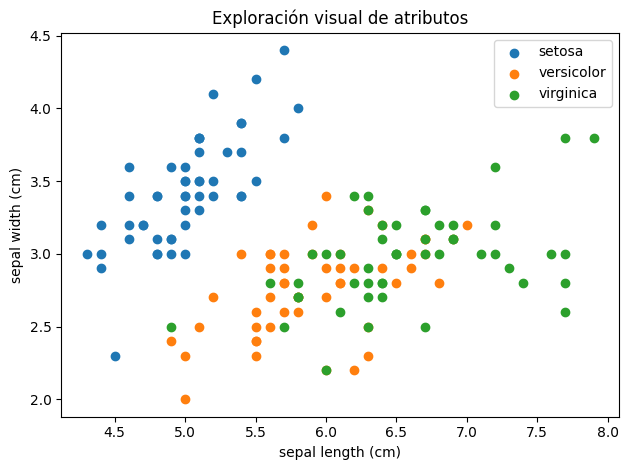

In [ ]:
for i, target_name in enumerate(data.target_names):
    plt.scatter(df.loc[df['target'] == i, df.columns[0]],
                df.loc[df['target'] == i, df.columns[1]],
                label=target_name)

plt.xlabel(df.columns[0])
plt.ylabel(df.columns[1])
plt.title('Exploración visual de atributos')
plt.legend()
plt.tight_layout()
plt.show()

El dataset Iris tiene tres clases objetivo, que corresponden a diferentes variedades de flores. Se modificó el código del scatter plot para incluir una leyenda que muestre la correspondencia entre los colores y nombres de las variedades de Iris usando `data.target_names`.

In [ ]:
print(data.target_names)

['setosa' 'versicolor' 'virginica']


El valor `target` en el DataFrame se asigna numéricamente:
*   `0`: setosa
*   `1`: versicolor
*   `2`: virginica

Para que el gráfico sea más claro, se añadió una leyenda que muestre esta correspondencia.

## 🧠 Desafío 2 — Vence al Modelo

Tu objetivo es **superar el accuracy obtenido por el modelo base** entrenado en esta actividad.

### Reglas:
- Podés modificar SOLO uno de estos elementos:
  - el tamaño del conjunto de prueba,
  - el modelo (cambiar LogisticRegression por otro simple),
  - o los atributos utilizados (seleccionar solo algunos).

### Pasos:
1. Elegí qué vas a modificar.
2. Entrená nuevamente el modelo.
3. Compará tu accuracy con el original.
4. Explicá por qué creés que tu cambio mejoró o empeoró el rendimiento.

### Bonus:
- Si lográs superar el accuracy por más de 5%, ganás el **Logro: Ajustador de Modelos**.